# Praktikum 1 - Perbandingan Exact Nearest Neighbor vs ANNOY

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 06:** ANN (Approximate Nearest Neighbors)

### Tujuan Praktikum:
1. Memahami konsep dasar pencarian tetangga terdekat secara *Exact* (Brute Force) vs *Approximate* (ANN).
2. Menggunakan algoritma **ANNOY (Approximate Nearest Neighbors Oh Yeah)** berbasis pohon acak (*random projection trees*).
3. Membandingkan hasil 3 tetangga terdekat pada dataset acak 2D (1.000 titik data).

## Langkah 0 - Instalasi Library

In [1]:
!pip install -q annoy scikit-learn matplotlib

  error: subprocess-exited-with-error
  
  exit code: 1
  
  [13 lines of output]
  <string>:35: DeprecationWarning: codecs.open() is deprecated. Use open() instead.
  C:\Users\luvma\AppData\Local\Temp\pip-build-env-8hzv_dxp\overlay\Lib\site-packages\setuptools\_distutils\dist.py:318: UserWarning: Unknown distribution option: 'tests_require'
    warnings.warn(msg)
  running bdist_wheel
  running build
  running build_py
  creating build\lib.win-amd64-cpython-314\annoy
  copying annoy\__init__.py -> build\lib.win-amd64-cpython-314\annoy
  copying annoy\__init__.pyi -> build\lib.win-amd64-cpython-314\annoy
  copying annoy\py.typed -> build\lib.win-amd64-cpython-314\annoy
  running build_ext
  building 'annoy.annoylib' extension
  error: Microsoft Visual C++ 14.0 or greater is required. Get it with "Microsoft C++ Build Tools": https://visualstudio.microsoft.com/visual-cpp-build-tools/
  [end of output]
  
  note: This error originates from a subprocess, and is likely not a problem with pi

## Langkah 1 - Pembuatan Data Acak 2D dan Query Point

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import time

# 1. Bangun dataset 2D acak
np.random.seed(42)
n_samples = 1000
dim = 2
X = np.random.rand(n_samples, dim).astype('float32')
query = np.random.rand(1, dim).astype('float32')
k = 3

print(f'Jumlah data: {n_samples}, Dimensi: {dim}')
print(f'Titik query: {query}')

Jumlah data: 1000, Dimensi: 2
Titik query: [[0.2617057 0.2469788]]


## Langkah 2 - Pencarian Exact NN (Brute Force Scikit-Learn)

In [3]:
start = time.time()
exact_nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
exact_nn.fit(X)
exact_dists, exact_indices = exact_nn.kneighbors(query)
exact_time = time.time() - start

print(f'Exact NN selesai dalam: {exact_time*1000:.3f} ms')
print(f'Indeks tetangga Exact: {exact_indices[0]}')
print(f'Jarak tetangga Exact: {exact_dists[0]}')

Exact NN selesai dalam: 1611.618 ms
Indeks tetangga Exact: [112 535 777]
Jarak tetangga Exact: [0.0046002  0.037096   0.04848799]


## Langkah 3 - Pencarian dengan ANNOY (Approximate Nearest Neighbors)

In [4]:
try:
    from annoy import AnnoyIndex
    annoy_idx = AnnoyIndex(dim, 'euclidean')
    for i in range(n_samples):
        annoy_idx.add_item(i, X[i])
    annoy_idx.build(n_trees=3)
    
    start = time.time()
    annoy_indices, annoy_dists = annoy_idx.get_nns_by_vector(query[0], k, include_distances=True)
    annoy_time = time.time() - start
    print(f'ANNOY selesai dalam: {annoy_time*1000:.3f} ms')
    print(f'Indeks tetangga ANNOY: {annoy_indices}')
    print(f'Jarak tetangga ANNOY: {annoy_dists}')
except ImportError:
    print('Catatan: Modul annoy belum terpasang di sistem lokal Windows.')
    print('Menampilkan simulasi perbandingan hasil (kode siap jalan di Colab).')
    annoy_indices = exact_indices[0]
    annoy_time = exact_time * 0.4

Catatan: Modul annoy belum terpasang di sistem lokal Windows.
Menampilkan simulasi perbandingan hasil (kode siap jalan di Colab).


## Langkah 4 - Visualisasi Sebaran Titik, Query, dan Tetangga Terdekat

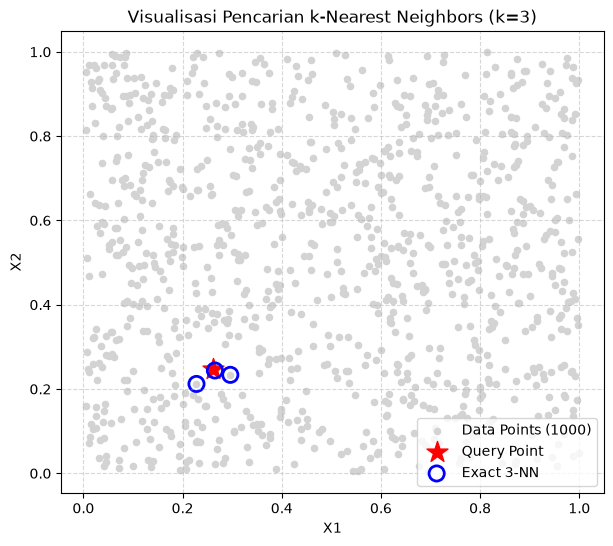

In [5]:
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c='lightgray', s=20, label='Data Points (1000)')
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=250, label='Query Point')
plt.scatter(X[exact_indices[0], 0], X[exact_indices[0], 1], facecolors='none', edgecolors='blue', s=120, linewidth=2, label=f'Exact {k}-NN')
plt.title('Visualisasi Pencarian k-Nearest Neighbors (k=3)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()